[*********************100%***********************]  1 of 1 completed


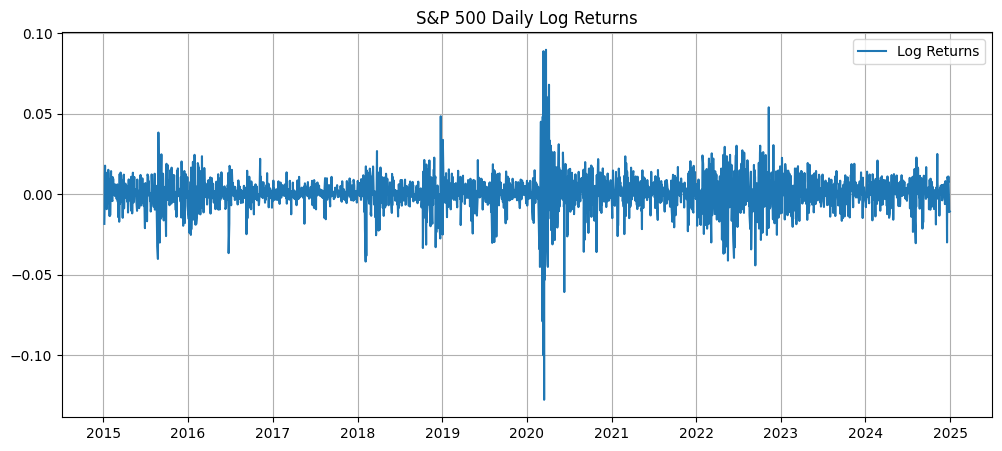

                     Constant Mean - GARCH Model Results                      
Dep. Variable:            Log_Returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3230.85
Distribution:                  Normal   AIC:                           6469.69
Method:            Maximum Likelihood   BIC:                           6493.01
                                        No. Observations:                 2514
Date:                Tue, Apr 29 2025   Df Residuals:                     2513
Time:                        16:09:51   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0795  1.485e-02      5.353  8.645e-08 [5.037e-0

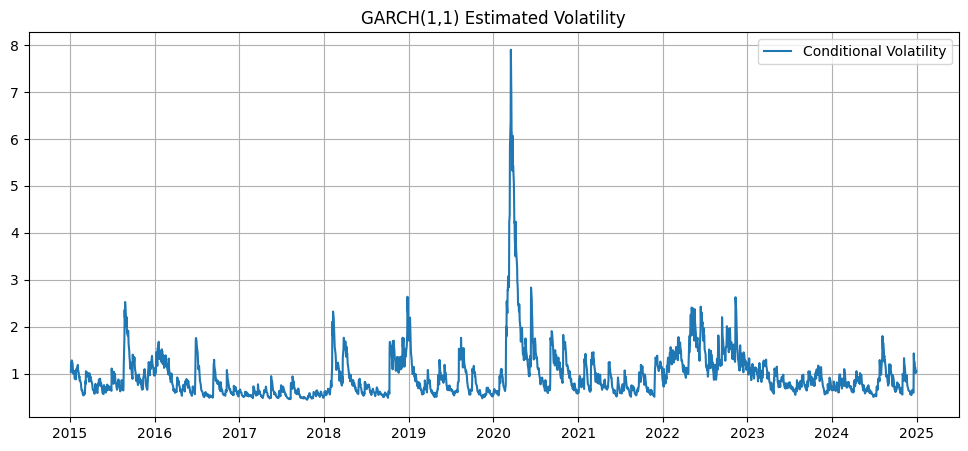

In [2]:
# ARCH/GARCH Modeling for S&P 500
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model

# 1. Download Data
data = yf.download("^GSPC", start="2015-01-01", end="2024-12-31", auto_adjust=True)
data['Log_Returns'] = np.log(data['Close'] / data['Close'].shift(1))
data = data.dropna()

# 2. Plot Returns
plt.figure(figsize=(12, 5))
plt.plot(data.index, data['Log_Returns'], label='Log Returns')
plt.title('S&P 500 Daily Log Returns')
plt.grid(True)
plt.legend()
plt.show()

# 3. Fit GARCH(1,1)
returns = 100 * data['Log_Returns']
model = arch_model(returns, vol='GARCH', p=1, q=1)
model_fit = model.fit(disp='off')

# 4. Print Summary
print(model_fit.summary())

# 5. Plot Volatility
plt.figure(figsize=(12, 5))
plt.plot(model_fit.conditional_volatility, label='Conditional Volatility')
plt.title('GARCH(1,1) Estimated Volatility')
plt.grid(True)
plt.legend()
plt.show()
